## Regularization

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import (
    LinearRegression, Lasso, Ridge, ElasticNet
)

from sklearn.metrics import r2_score

In [2]:
data = {
    'Study_Hours': [6, 1, 4, 4, 8, 4, 6, 3, 5, 8],

    'Mobile_Usage': [6, 9, 6, 6, 4, 7, 6, 9, 5, 3],

    'Sleep_Hours': [7.0, 4.8, 5.7, 6.6, 7.4,
                    6.0, 6.1, 5.6, 6.3, 8.0],

    'Exam_Marks': [67.2, 37.8, 59.2, 69.9, 86.1,
                   61.2, 80.6, 61.8, 70.4, 89.8]
}

df = pd.DataFrame(data)

print("STUDENT DATASET")
print(df)

STUDENT DATASET
   Study_Hours  Mobile_Usage  Sleep_Hours  Exam_Marks
0            6             6          7.0        67.2
1            1             9          4.8        37.8
2            4             6          5.7        59.2
3            4             6          6.6        69.9
4            8             4          7.4        86.1
5            4             7          6.0        61.2
6            6             6          6.1        80.6
7            3             9          5.6        61.8
8            5             5          6.3        70.4
9            8             3          8.0        89.8


In [3]:
X = df.drop('Exam_Marks', axis=1)

y = df['Exam_Marks']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=4
)

In [5]:
models = {

    'Linear Regression': make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    'Lasso': make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.5, max_iter=100000)
    ),

    'Ridge': make_pipeline(
        StandardScaler(),
        Ridge(alpha=0.5)
    ),

    'Elastic Net': make_pipeline(
        StandardScaler(),
        ElasticNet(
            alpha=0.3,
            l1_ratio=0.3,
            max_iter=100000
        )
    )
}

In [6]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)

    test_pred = model.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)

    test_r2 = r2_score(y_test, test_pred)

    gap = train_r2 - test_r2

    results.append({
        'Model': name,
        'Training R2': train_r2,
        'Testing R2': test_r2,
        'Train-Test Gap': gap
    })

In [7]:
results_df = pd.DataFrame(results)

print(results_df.round(6).to_string(index=False))

            Model  Training R2  Testing R2  Train-Test Gap
Linear Regression     0.929674   -0.418410        1.348083
            Lasso     0.902370    0.539021        0.363349
            Ridge     0.892122    0.647030        0.245091
      Elastic Net     0.852875    0.847171        0.005704


In [8]:
coefficient_comparison = pd.DataFrame({
    'Feature': X.columns
})

for name, model in models.items():

    # Extract the final estimator from pipeline
    estimator = list(model.named_steps.values())[-1]

    coefficient_comparison[name] = estimator.coef_


print("COEFFICIENT COMPARISON")

print(coefficient_comparison.round(3).to_string(index=False))

COEFFICIENT COMPARISON
     Feature  Linear Regression  Lasso  Ridge  Elastic Net
 Study_Hours             23.064 14.139 12.524        8.186
Mobile_Usage              4.118  0.000 -0.284       -2.137
 Sleep_Hours             -4.922 -0.000  1.018        2.843


In [9]:
lasso_coef = models['Lasso'].named_steps['lasso'].coef_

lasso_result = pd.DataFrame({
    'Feature': X.columns,
    'Lasso_Coefficient': lasso_coef
})

print("LASSO ZERO COEFFICIENT FEATURES")

print(
    lasso_result[lasso_result['Lasso_Coefficient'] == 0]
)

LASSO ZERO COEFFICIENT FEATURES
        Feature  Lasso_Coefficient
1  Mobile_Usage                0.0
2   Sleep_Hours               -0.0


 ## Polynomial Features

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [11]:
# Step 1: Create sample dataset
df = pd.DataFrame({
    "Hours_Studied": [1, 2, 3, 4, 5, 6],
    "Marks": [20, 25, 35, 50, 70, 95]
})

print("Dataset:")
print(df)

Dataset:
   Hours_Studied  Marks
0              1     20
1              2     25
2              3     35
3              4     50
4              5     70
5              6     95


In [12]:
# Step 2: Separate input and output
X = df[["Hours_Studied"]]
y = df["Marks"]

In [13]:
# Step 3: Train Simple Linear Regression

linear_model = LinearRegression()  
linear_model.fit(X, y)             
linear_predictions = linear_model.predict(X)  

In [14]:
# Step 4: Create Polynomial Features (Degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

In [15]:
# Step 5: Train Polynomial Regression
polynomial_model = LinearRegression()
polynomial_model.fit(X_poly, y)

polynomial_predictions = polynomial_model.predict(X_poly)

In [16]:
# Step 6: Compare model performance
results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Polynomial Regression (Degree 2)"
    ],
    "R2 Score": [
        r2_score(y, linear_predictions),
        r2_score(y, polynomial_predictions)
    ],
    "MAE": [
        mean_absolute_error(y, linear_predictions),
        mean_absolute_error(y, polynomial_predictions)
    ],
    "MSE": [
        mean_squared_error(y, linear_predictions),
        mean_squared_error(y, polynomial_predictions)
    ]
})

print("Model Comparison:")
print(results.round(3).to_string(index=False))

Model Comparison:
                           Model  R2 Score   MAE    MSE
        Simple Linear Regression     0.944 5.556 38.889
Polynomial Regression (Degree 2)     1.000 0.000  0.000


In [17]:
# Step 7: Display model equations
print("\nSimple Linear Regression Equation:")
print(
    f"Marks = {linear_model.coef_[0]:.3f} * Hours "
    f"+ {linear_model.intercept_:.3f}"
)

print("\nPolynomial Regression Equation:")
print(
    f"Marks = {polynomial_model.intercept_:.3f} "
    f"+ ({polynomial_model.coef_[0]:.3f} * X) "
    f"+ ({polynomial_model.coef_[1]:.3f} * X^2)"
)


Simple Linear Regression Equation:
Marks = 15.000 * Hours + -3.333

Polynomial Regression Equation:
Marks = 20.000 + (-2.500 * X) + (2.500 * X^2)


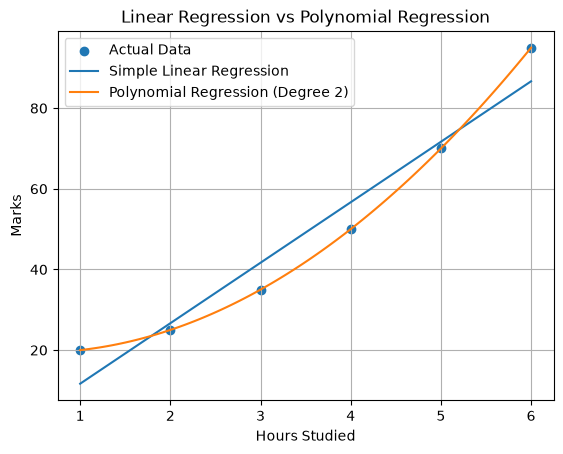

In [18]:
# Step 9: Plot both models
X_curve = pd.DataFrame({
    "Hours_Studied": np.linspace(1, 6, 100)
})

linear_curve = linear_model.predict(X_curve)

polynomial_curve = polynomial_model.predict(
    poly.transform(X_curve)
)

plt.scatter(X, y, label="Actual Data")
plt.plot(
    X_curve["Hours_Studied"],
    linear_curve,
    label="Simple Linear Regression"
)
plt.plot(
    X_curve["Hours_Studied"],
    polynomial_curve,
    label="Polynomial Regression (Degree 2)"
)

plt.xlabel("Hours Studied")
plt.ylabel("Marks")
plt.title("Linear Regression vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Step 8: Predict marks for 4.5 hours
new_data = pd.DataFrame({"Hours_Studied": [1]})

linear_prediction = linear_model.predict(new_data)

new_data_poly = poly.transform(new_data)
polynomial_prediction = polynomial_model.predict(new_data_poly)

print("Prediction for given Hours:")
print(f"Simple Linear Regression: {linear_prediction[0]:.2f}")
print(f"Polynomial Regression: {polynomial_prediction[0]:.2f}")

Prediction for given Hours:
Simple Linear Regression: 11.67
Polynomial Regression: 20.00


### OLS

In [1]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
data = {
    "Study_Hours":[1,2,3,4,5,6,7,8,9,10],
    "Marks":[20,30,40,50,60,65,75,80,90,95]
}

df = pd.DataFrame(data)
print(df)

   Study_Hours  Marks
0            1     20
1            2     30
2            3     40
3            4     50
4            5     60
5            6     65
6            7     75
7            8     80
8            9     90
9           10     95


In [3]:
X = df[["Study_Hours"]]
y = df["Marks"]

In [4]:
model = LinearRegression()

In [5]:
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[8.33]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Study_Hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.67
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 8.33333333333333
Intercept: 14.666666666666686


In [9]:
y_pred = model.predict(X)
df["Predicted_Marks"] = y_pred
print(df)

   Study_Hours  Marks  Predicted_Marks
0            1     20        23.000000
1            2     30        31.333333
2            3     40        39.666667
3            4     50        48.000000
4            5     60        56.333333
5            6     65        64.666667
6            7     75        73.000000
7            8     80        81.333333
8            9     90        89.666667
9           10     95        98.000000


In [10]:
df["Residuals"] = y - y_pred
print(df)

   Study_Hours  Marks  Predicted_Marks  Residuals
0            1     20        23.000000  -3.000000
1            2     30        31.333333  -1.333333
2            3     40        39.666667   0.333333
3            4     50        48.000000   2.000000
4            5     60        56.333333   3.666667
5            6     65        64.666667   0.333333
6            7     75        73.000000   2.000000
7            8     80        81.333333  -1.333333
8            9     90        89.666667   0.333333
9           10     95        98.000000  -3.000000


In [11]:
MSE = mean_squared_error(y, y_pred)
print("MSE:", MSE)

MSE: 4.33333333333333
